<a href="https://colab.research.google.com/github/marpablo/Marian_INFO4670_Fall2026/blob/main/INFO_4670_Assignment_4.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Assignment 4

Name: Marian Pablo

Date: 10/17/2026

# Step 1: Import Libraries and Load Data

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix, accuracy_score, classification_report


In [4]:
data = pd.read_csv('car_purchase_data.csv')
display(data.head())
print('Shape:', data.shape)

,User ID,Gender,Age,Salary,Purchased
0,15624510,Male,19,19000,0
1,15810944,Male,35,20000,0
2,15668575,Female,26,43000,0
3,15603246,Female,27,57000,0
4,15804002,Male,19,76000,0


Shape: (400, 5)


# Step 2: Split Features and Target

In [5]:
X = data[['Age', 'Salary']]
Y = data['Purchased']


In [6]:
print('X shape:', X.shape)
print('Y distribution:\n', Y.value_counts())

X shape: (400, 2)
Y distribution:
 Purchased
0    257
1    143
Name: count, dtype: int64


# Step 3: Train/Test Split

In [7]:
X_train, X_test, Y_train, Y_test = train_test_split(
    X, Y, test_size=0.2, random_state=42, stratify=Y
)


In [8]:
print('Train size:', X_train.shape[0], 'Test size:', X_test.shape[0])

Train size: 320 Test size: 80


## Step 4: Feature Scaling

In [9]:
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

In [10]:
print('Scaling complete')

Scaling complete


# Step 5: Train Logistic Regression Model

In [11]:
model = LogisticRegression(max_iter=1000, random_state=42)
model.fit(X_train, Y_train)

LogisticRegression(max_iter=1000, random_state=42)

In [12]:
print('Model trained.')

Model trained.


## Step 6: Predict and Evaluate

In [13]:
y_pred = model.predict(X_test)
acc = accuracy_score(Y_test, y_pred)
cm = confusion_matrix(Y_test, y_pred)


In [14]:
print ('Accuracy:', acc)
print('\nConfusion Matrix:\n', cm)
print('\nClassification Report:\n', classification_report(Y_test, y_pred))

Accuracy: 0.8375

Confusion Matrix:
 [[48  3]
 [10 19]]

Classification Report:
               precision    recall  f1-score   support

           0       0.83      0.94      0.88        51
           1       0.86      0.66      0.75        29

    accuracy                           0.84        80
   macro avg       0.85      0.80      0.81        80
weighted avg       0.84      0.84      0.83        80



# Step 7: Visualization of Decision Regions

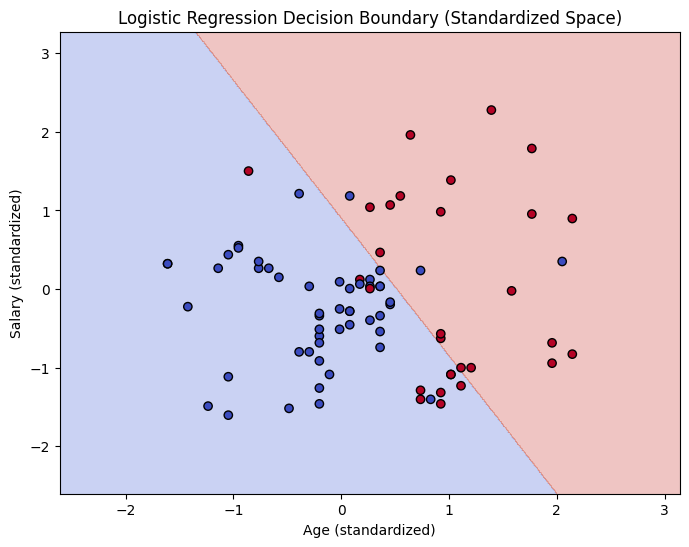

In [15]:
import numpy as np
import matplotlib.pyplot as plt

X_set, y_set = X_test[:, :2], Y_test.values
model_2d = LogisticRegression(max_iter=1000)
model_2d.fit(X_train[:, :2], Y_train)

x1_min, x1_max = X_set[:, 0].min() - 1, X_set[:, 0].max() + 1
x2_min, x2_max = X_set[:, 1].min() - 1, X_set[:, 1].max() + 1
X1, X2 = np.meshgrid(
    np.arange(start=x1_min, stop=x1_max, step=0.01),
    np.arange(start=x2_min, stop=x2_max, step=0.01)
)

Z = model_2d.predict(np.array([X1.ravel(), X2.ravel()]).T)
Z = Z.reshape(X1.shape)

plt.figure(figsize=(8, 6))
plt.contourf(X1, X2, Z, alpha=0.3, cmap='coolwarm')
plt.scatter(X_set[:, 0], X_set[:, 1], c=y_set, edgecolor='k', cmap='coolwarm')
plt.title('Logistic Regression Decision Boundary (Standardized Space)')
plt.xlabel('Age (standardized)')
plt.ylabel('Salary (standardized)')
plt.show()

# Reflection Questions



**1. Logistic regression outputs probabilites - why can it still be used for classification?**

A: Logistic regression can be used to predict the probability a data point belongs to a certain classification as an output.


**2. Based on your mode, which customers are most likely to purchase a car?**

A: Those who are older and have higher salaries are most likely to purchase a car based on the mode.


**3. What factors might cause low accuracy in this task?**

Ommitted predictors, lack of scaling, and linear boundaries.


**4. Propose additional features or preprocessing steps that could improve accuracy.**

A: Additional features such as class weight can be adjusted and adding possible feature engineering.